# Auditoria y limpieza de datos GMN

Este cuaderno registra la carga, inspección y limpieza de los datos utilizados en el proyeco de las Gemínidas.

In [75]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [6]:
# Definir la raíz del proyecto y las rutas de las carpetas que se utilizarán

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
    
RAW_DIR = PROJECT_ROOT / "data" / "raw"
INTERIM_DIR = PROJECT_ROOT / "data" / "interim"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
TABLES_DIT = PROJECT_ROOT / "reports" / "tables"

PROJECT_ROOT

PosixPath('/Users/alexn/Documents/Uni_Itesm/Tercer semestre/F1009/Investigacion')

In [9]:
# Construir la ruta del archivo de 2019 y comprobar que fue descargado correctamente

raw_file = RAW_DIR / "traj_summary_monthly_201912.txt"

print("Archivo encontrado: ", raw_file.exists())
print("Ruta: ", raw_file)
print("Tamaño en MB: ", raw_file.stat().st_size / 1_000_000)

Archivo encontrado:  True
Ruta:  /Users/alexn/Documents/Uni_Itesm/Tercer semestre/F1009/Investigacion/data/raw/traj_summary_monthly_201912.txt
Tamaño en MB:  10.328228


In [21]:
# Mostrar las primeras diez líneas sin modificar ni cargar todavía toda la base

with raw_file.open(
    "r",
    encoding = "utf-8",
    errors = "replace"
) as file:
    for _ in range(10):
        print(file.readline().rstrip())

# Summary generated on 2026-10-30 23:36:11.534390+00:00 UTC

#  Unique trajectory;      Beginning      ;        Beginning          ;   IAU;   IAU;   Sol lon ;   App LST ;   RAgeo  ;   +/-  ;   DECgeo ;   +/-  ;  LAMgeo  ;   +/-  ;   BETgeo ;   +/-  ;    Vgeo  ;    +/- ;  LAMhel  ;   +/-  ;   BEThel ;   +/-  ;    Vhel  ;    +/- ;       a    ;   +/-  ;      e    ;   +/-  ;      i    ;   +/-  ;    peri   ;    +/-  ;    node   ;    +/-  ;     Pi    ;   +/-  ;      b    ;   +/-  ;      q    ;   +/-  ;      f    ;   +/-  ;      M    ;   +/-  ;       Q    ;   +/-  ;      n    ;   +/-  ;      T    ;   +/-  ; TisserandJ;   +/-  ;   RAapp  ;   +/-  ;   DECapp ;   +/-  ;  Azim +E ;   +/-  ;    Elev  ;   +/-  ;   Vinit  ;    +/- ;    Vavg  ;    +/- ;    LatBeg   ;   +/-  ;    LonBeg   ;   +/-  ;   HtBeg ;   +/-  ;    LatEnd   ;   +/-  ;    LonEnd   ;   +/-  ;   HtEnd ;   +/-  ; Duration;  Peak ;  Peak Ht;   F  ;  Mass kg;   Qc ; MedianFitErr; Beg in; End in;  Num;      Participating

#      identi

In [28]:
# Cargar el archivo GMN como DataFrame conservando sus dos filas de encabezado

df_raw = pd.read_csv(
    raw_file,
    engine = "python",
    sep = ";",
    skipinitialspace = True,
    skiprows = [0, 5, 6],
    header = [0, 1],
    na_values = ["nan", "None"],
)

print("Número de filas: ", df_raw.shape[0])
print("Número de columnas: ", df_raw.shape[1])

display(df_raw.head(3))

Número de filas:  11143
Número de columnas:  86


#  Unique trajectory  Beginning               Beginning           IAU       \
   #      identifier    Julian date               UTC Time            No code   
0  20191201000031_ghvfm     2.458819e+06  2019-12-01 00:00:31.996809  -1  ...   
1  20191201000058_C6rji     2.458819e+06  2019-12-01 00:00:58.131851  -1  ...   
2  20191201000253_e8sNU     2.458819e+06  2019-12-01 00:02:53.756370  16  HYD   

     Sol lon    App LST     RAgeo     +/-     DECgeo   ...  Peak    Peak Ht  \
       deg        deg        deg     sigma     deg     ... AbsMag      km     
0  248.210867  84.591665  143.02114  0.8854  26.41041  ...   1.19  107.9686   
1  248.211174  84.292021   68.29109  1.2096  24.78505  ...   1.03   85.2442   
2  248.212530  84.323282  118.55018  0.1622   3.93950  ...  -1.80   93.8287   

     F     Mass kg    Qc  MedianFitErr Beg in End in  Num  \
   param  tau=0.7%   deg     arcsec      FOV    FOV  stat   
0  0.500  0.000007  11.41        42.15   True   True    2   
1  0.740  0.000088   7.88        44.21   True   True    2   
2  0.641  0.000290  40.65        73.98   True   True    4   

             Participating      
                stations        
0                HR0007,HR000N  
1                HR0007,HR000N  
2  HR000F,HR000K,HR000P,HR000U  

[3 rows x 86 columns]

In [29]:
# Mostrar los primeros encabezados

print("Tipos del encabezado: ", type(df_raw.columns))
print("Número de niveles", df_raw.columns.nlevels)

display(
    pd.DataFrame(
        df_raw.columns[:15].tolist(),
        columns = ["Nivel 1: nombre", "Nivel 2: unidad"],
    )
)

Tipos del encabezado:  <class 'pandas.MultiIndex'>
Número de niveles 2


,Nivel 1: nombre,Nivel 2: unidad
0,# Unique trajectory,# identifier
1,Beginning,Julian date
2,Beginning,UTC Time
3,IAU,No
4,IAU,code
5,Sol lon,deg
6,App LST,deg
7,RAgeo,deg
8,+/-,sigma
9,DECgeo,deg


In [30]:
# Unir los dos niveles del encabezado en un solo nombre por columna

def clean_header_text(text):
    cleaned_text = str(text).replace("#", "")
    cleaned_text = " " .join(cleaned_text.split())

    return cleaned_text


flattened_columns = []

for main_name, secondary_name in df_raw.columns:
    main_name = clean_header_text(main_name)
    secondary_name = clean_header_text(secondary_name)

    if secondary_name.startswith("Unnamed"):
        final_name = main_name
    else:
        final_name = f"{main_name} ({secondary_name})"

    flattened_columns.append(final_name)


df_raw.columns = flattened_columns

for column_name in df_raw.columns[:15]:
    print(column_name)

Unique trajectory (identifier)
Beginning (Julian date)
Beginning (UTC Time)
IAU (No)
IAU (code)
Sol lon (deg)
App LST (deg)
RAgeo (deg)
+/- (sigma)
DECgeo (deg)
+/- (sigma .1)
LAMgeo (deg)
+/- (sigma .2)
BETgeo (deg)
+/- (sigma .3)


In [31]:
# Renombrar cada columna de incertidumbre usando el nombre de la variable anterior

renamed_columns = list(df_raw.columns)

for column_position, column_name in enumerate(renamed_columns):
    if column_name.startswith("+/-"):
        previous_column = renamed_columns[column_position - 1]
        parameter_name = previous_column.split(" ")[0]
        
        renamed_columns[column_position] = (
            f"{parameter_name}_sigma"
        )
        
df_raw.columns = renamed_columns

print("¿Todos los nombres son únicos?: ", df_raw.columns.is_unique)

for column_name in df_raw.columns:
    if column_name.endswith("_sigma"):
        print(column_name)

¿Todos los nombres son únicos?:  True
RAgeo_sigma
DECgeo_sigma
LAMgeo_sigma
BETgeo_sigma
Vgeo_sigma
LAMhel_sigma
BEThel_sigma
Vhel_sigma
a_sigma
e_sigma
i_sigma
peri_sigma
node_sigma
Pi_sigma
b_sigma
q_sigma
f_sigma
M_sigma
Q_sigma
n_sigma
T_sigma
TisserandJ_sigma
RAapp_sigma
DECapp_sigma
Azim_sigma
Elev_sigma
Vinit_sigma
Vavg_sigma
LatBeg_sigma
LonBeg_sigma
HtBeg_sigma
LatEnd_sigma
LonEnd_sigma
HtEnd_sigma


In [36]:
# Comprobar dimensiones, tipos generales y primeras columnas del DataFrame cargado

print("Filas: ", df_raw.shape[0])
print("Columnas: ", df_raw.shape[1])
print("Nombres únicos: ", df_raw.columns.is_unique)

print("\n Información general: ")
df_raw.info(verbose = False)

print("\n Primeras tres filas y primeras doce columnas: ")

display(df_raw.iloc[:3, :12])

Filas:  11143
Columnas:  86
Nombres únicos:  True

 Información general: 
<class 'pandas.DataFrame'>
RangeIndex: 11143 entries, 0 to 11142
Columns: 86 entries, Unique trajectory (identifier) to Participating (stations)
dtypes: bool(2), float64(78), int64(2), str(4)
memory usage: 7.2 MB

 Primeras tres filas y primeras doce columnas: 


,Unique trajectory (identifier),Beginning (Julian date),Beginning (UTC Time),IAU (No),IAU (code),Sol lon (deg),App LST (deg),RAgeo (deg),RAgeo_sigma,DECgeo (deg),DECgeo_sigma,LAMgeo (deg)
0,20191201000031_ghvfm,2.458819e+06,2019-12-01 00:00:31.996809,-1,...,248.210867,84.591665,143.02114,0.8854,26.41041,0.1940,136.82863
1,20191201000058_C6rji,2.458819e+06,2019-12-01 00:00:58.131851,-1,...,248.211174,84.292021,68.29109,1.2096,24.78505,0.4855,70.35293
2,20191201000253_e8sNU,2.458819e+06,2019-12-01 00:02:53.756370,16,HYD,248.212530,84.323282,118.55018,0.1622,3.93950,0.2990,119.83537


In [39]:
# Crear una copia del trabajo y registrar el archivo y año de procedencia

df = df_raw.copy()

df["source_file"] = raw_file.name
df["source_year"] = 2019

print("Dimensiones del original: ", df_raw.shape)
print("DImensiones de la copia: ", df.shape)

display(
    df[
        [
            "Unique trajectory (identifier)",
            "source_file",
            "source_year",
        ]
    ].head(3)
)

Dimensiones del original:  (11143, 86)
DImensiones de la copia:  (11143, 88)


,Unique trajectory (identifier),source_file,source_year
0,20191201000031_ghvfm,traj_summary_monthly_201912.txt,2019
1,20191201000058_C6rji,traj_summary_monthly_201912.txt,2019
2,20191201000253_e8sNU,traj_summary_monthly_201912.txt,2019


In [40]:
# Normalizar los textos y registrar si había campos vacíos no reconocidos como faltantes

text_columns = [
    "Unique trajectory (identifier)",
    "IAU (code)",
    "Participating (stations)",
]

missing_before = df_raw[text_columns].isna().sum()

for column in text_columns:
    df[column] = (df_raw[column].astype("string").str.strip().replace("", pd.NA))

text_report = pd.DataFrame(
    {
        "faltantes_antes": missing_before,
        "faltantes_después": df[text_columns].isna().sum(),
    }
)

display(text_report)
display(df[text_columns].head(3))

,faltantes_antes,faltantes_después
Unique trajectory (identifier),0,0
IAU (code),0,0
Participating (stations),0,0


,Unique trajectory (identifier),IAU (code),Participating (stations)
0,20191201000031_ghvfm,...,"HR0007,HR000N"
1,20191201000058_C6rji,...,"HR0007,HR000N"
2,20191201000253_e8sNU,HYD,"HR000F,HR000K,HR000P,HR000U"


In [44]:
# Convertir las fechas a datetime en UTx y comprobar su rango y valores faltantes

date_column = "Beginning (UTC Time)"

date_text = (df_raw[date_column].astype("string").str.strip().replace("", pd.NA))

df[date_column] = pd.to_datetime(date_text, format = "%Y-%m-%d %H:%M:%S.%f", errors = "raise", utc = True)

print("Tipos después de convertir: ", df[date_column].dtype)
print("Fechas faltantes antes: ", date_text.isna().sum())
print("Fechas faltantes después: ", df[date_column].isna().sum())
print("Fecha más temprana: ", df[date_column].min())
print("Fecha más tardía: ", df[date_column].max())

display(
    pd.DataFrame(
        {
            "texto_original ": df_raw[date_column].head(3),
            "fecha_interpretada ": df[date_column].head(3),
        }
    )
)

Tipos después de convertir:  datetime64[us, UTC]
Fechas faltantes antes:  0
Fechas faltantes después:  0
Fecha más temprana:  2019-12-01 00:00:31.996809+00:00
Fecha más tardía:  2019-12-31 23:57:18.061349+00:00


,texto_original,fecha_interpretada
0,2019-12-01 00:00:31.996809,2019-12-01 00:00:31.996809+00:00
1,2019-12-01 00:00:58.131851,2019-12-01 00:00:58.131851+00:00
2,2019-12-01 00:02:53.756370,2019-12-01 00:02:53.756370+00:00


In [ ]:
# Revisar los tipos principales y contar los valores de las columnas booleanas

columns_to_check = [
    "Unique trajectory (identifier)",
    "Beginning (UTC Time)",
    "IAU (No)",
    "IAU (code)",
    "Num (stat)",
    "Beg in (FOV)",
    "End in (FOV)",
    "Participating (stations)",
]

type_report = df[columns_to_check].dtypes.to_frame(name = "tipo")

display(type_report)

boolean_columns = [
    "Beg in (FOV)",
    "End in (FOV)",
]

for column in boolean_columns:
    print("\n Columna:", column)
    display(df[column].value_counts(dropna = False))
    
print("\n Filas originales: ", len(df_raw))
print("Filas actuales: ", len(df))

,tipo
Unique trajectory (identifier),string
Beginning (UTC Time),"datetime64[us, UTC]"
IAU (No),int64
IAU (code),string
Num (stat),int64
Beg in (FOV),bool
End in (FOV),bool
Participating (stations),string



 Columna: Beg in (FOV)


Beg in (FOV)
True     11108
False       35
Name: count, dtype: int64


 Columna: End in (FOV)


End in (FOV)
True     11084
False       59
Name: count, dtype: int64


 Filas originales:  11143
Filas actuales:  11143
(11143, 88)


In [47]:
# Resumir la cantidad y el porcentaje de variables faltantes por columna

missing_report = pd.DataFrame(
    {
        "disponibles": df.notna().sum(),
        "faltantes": df.isna().sum(),
        "porcentaje_faltante": df.isna().mean() * 100,
    }
)

missing_report = missing_report.sort_values(
    "porcentaje_faltante",
    ascending = False,
)

print("Número de filas analizadas: ", len(df))
print("Columnas con al menos un faltante: ", (missing_report["faltantes"] > 0).sum())
display(
    missing_report.loc[
        missing_report["faltantes"] > 0
    ].round(2)
)

Número de filas analizadas:  11143
Columnas con al menos un faltante:  6


,disponibles,faltantes,porcentaje_faltante
b_sigma,0,11143,100.00
M_sigma,9501,1642,14.74
T_sigma,9501,1642,14.74
T (years),10363,780,7.00
M (deg),10363,780,7.00
node_sigma,11141,2,0.02


In [48]:
# Revisar la disponiblidad de las variables importantes para el análisis
analysis_columns = [
    "Unique trajectory (identifier)",
    "Beginning (UTC Time)",
    "IAU (code)",
    "Sol lon (deg)",
    "RAgeo (deg)",
    "RAgeo_sigma",
    "DECgeo (deg)",
    "DECgeo_sigma",
    "LAMgeo (deg)",
    "BETgeo (deg)",
    "Vgeo (km/s)",
    "Vgeo_sigma",
    "Peak (AbsMag)",
    "Qc (deg)",
    "MedianFitErr (arcsec)",
    "Num (stat)",
    "Beg in (FOV)",
    "End in (FOV)",
]

analysis_missing_report = missing_report.loc[analysis_columns].copy()

display(analysis_missing_report.round(2))

,disponibles,faltantes,porcentaje_faltante
Unique trajectory (identifier),11143,0,0.0
Beginning (UTC Time),11143,0,0.0
IAU (code),11143,0,0.0
Sol lon (deg),11143,0,0.0
RAgeo (deg),11143,0,0.0
RAgeo_sigma,11143,0,0.0
DECgeo (deg),11143,0,0.0
DECgeo_sigma,11143,0,0.0
LAMgeo (deg),11143,0,0.0
BETgeo (deg),11143,0,0.0


In [50]:
# Detectar filas duplicadas e identificadores de trayectoria repetidos sin eliminar observaciones

id_column = "Unique trajectory (identifier)"

duplicate_id_mask = df.duplicated(subset = [id_column], keep = False)

duplicate_summary = pd.DataFrame(
    {
        "medida": [
            "Filas totales",
            "Identificadores únicos",
            "Filas con un ID repetido",
            "Identificadores que aparecen más de una vez",
            "Filas adicionales por repetición de ID",
            "Filas completamente duplicadas adicionales"
        ],
        "valor": [
            len(df),
            df[id_column].nunique(dropna = False),
            duplicate_id_mask.sum(),
            df.loc[duplicate_id_mask, id_column].nunique(),
            df.duplicated(subset = [id_column], keep = "first").sum(),
            df.duplicated(keep = "first").sum(),
        ],
    }
)

display(duplicate_summary)

if duplicate_id_mask.any():
    duplicate_review_columns = [
        id_column,
        "Beginning (UTC Time)",
        "IAU (No)",
        "IAU (code)",
        "Sol lon (deg)",
        "RAgeo (deg)",
        "DECgeo (deg)",
        "Vgeo (km/s)",
        "Peak (AbsMag)",
        "source_file",
    ]
    
    duplicate_review = (
        df.loc[
            duplicate_id_mask,
            duplicate_review_columns,
        ]
        .sort_values(id_column)
    )
    
    print("Primeros identificadores repetidos: ")
    display(duplicate_review.head(20))
    
else:
    print("No se encontraron identificadores repetidos.")

,medida,valor
0,Filas totales,11143
1,Identificadores únicos,11143
2,Filas con un ID repetido,0
3,Identificadores que aparecen más de una vez,0
4,Filas adicionales por repetición de ID,0
5,Filas completamente duplicadas adicionales,0


No se encontraron identificadores repetidos.


In [53]:
# Comprobar que las variables principales estén dentro de rangos matemáticos y físicos válidos

reglas_validez = {
    "Longitud solar fuera de [0, 360)": (
        df["Sol lon (deg)"].ge(0)
        & df["Sol lon (deg)"].lt(360)
    ),
    
    "Ascensión recta fuera de [0, 360)": (
      df["RAgeo (deg)"].ge(0)
      & df["RAgeo (deg)"].lt(360)
    ),
    
    "Declinación fuera se [-90, 90]": (
        df["DECgeo (deg)"].between(-90,90)
    ),
    
    "Longitud eclíptica fuera de [0, 360)": (
        df["LAMgeo (deg)"].ge(0)
        & df["LAMgeo (deg)"].lt(360)
    ),
    
    "Latitud eclíptica fuera de [-90, 90]": (
        df["BETgeo (deg)"].between(-90, 90)
    ),
    
    "Velocidad geocéntrica no positiva": (
        df["Vgeo (km/s)"].gt(0)
    ),
    
    "Incertidumbre de RA negativa": (
        df["RAgeo_sigma"].ge(0)
    ),
    
    "Incertidumbre de DEC negativa": (
        df["DECgeo_sigma"].ge(0)
    ),
    
    "Incertidumbre de velocidad negativa": (
        df["Vgeo_sigma"].ge(0)
    ),
    
    "Ángulo de convergencia fuera de [0, 180]": (
        df["Qc (deg)"].between(0, 180)
    ),
    
    "Error de ajuste negativo": (
        df["MedianFitErr (arcsec)"].ge(0)
    ),
    
    "Menos de dos estaciones": (
        df["Num (stat)"].ge(2)
    )
}

resultados_rangos = []

for descripcion, mascara_valida in reglas_validez.items():
    mascara_invalida = ~mascara_valida.fillna(False)
    cantidad_invalida = mascara_invalida.sum()
    
    resultados_rangos.append(
        {
            "comprobación": descripcion,
            "filas_invalidas": cantidad_invalida,
            "porcentaje_invalido": round(
                100 * cantidad_invalida / len(df),
                4,
            ),
        }
    )
    
auditoria_rangos = pd.DataFrame(resultados_rangos)

display(auditoria_rangos)

,comprobación,filas_invalidas,porcentaje_invalido
0,"Longitud solar fuera de [0, 360)",0,0.0
1,"Ascensión recta fuera de [0, 360)",0,0.0
2,"Declinación fuera se [-90, 90]",0,0.0
3,"Longitud eclíptica fuera de [0, 360)",0,0.0
4,"Latitud eclíptica fuera de [-90, 90]",0,0.0
5,Velocidad geocéntrica no positiva,0,0.0
6,Incertidumbre de RA negativa,0,0.0
7,Incertidumbre de DEC negativa,0,0.0
8,Incertidumbre de velocidad negativa,0,0.0
9,"Ángulo de convergencia fuera de [0, 180]",0,0.0


In [54]:
# Resumir la distribución de las variables físicas y de calidad antes de definir filtros

columnas_diagnostico = [
    "RAgeo_sigma",
    "DECgeo_sigma",
    "Vgeo_sigma",
    "Qc (deg)",
    "MedianFitErr (arcsec)",
    "Num (stat)",
    "Vgeo (km/s)",
    "Peak (AbsMag)",
]

resumen_diagnostico = (
    df[columnas_diagnostico]
    .describe(
        percentiles = [
            0.01,
            0.05,
            0.25,
            0.50,
            0.75,
            0.95,
            0.99,
        ]
    )
    .T
    .rename(
        columns = {
            "count": "cantidad",
            "mean": "media",
            "std": "desviacion_estandar",
            "min": "minimo",
            "1%": "percentil_1",
            "5%": "percentil_5",
            "25%": "percentil_25",
            "50%": "mediana",
            "75%": "percentil_75",
            "95%": "percentil_95",
            "99%": "percentil_99",
            "max": "maximo",
        }
    )
    .round(4)
)

display(resumen_diagnostico)

,cantidad,media,desviacion_estandar,minimo,percentil_1,percentil_5,percentil_25,mediana,percentil_75,percentil_95,percentil_99,maximo
RAgeo_sigma,11143.0,0.5493,0.7313,0.0073,0.0239,0.0547,0.1610,0.3369,0.6910,1.6464,3.1885,21.9504
DECgeo_sigma,11143.0,0.3947,0.3591,0.0050,0.0277,0.0539,0.1384,0.2714,0.5290,1.1835,1.6304,1.9595
Vgeo_sigma,11143.0,0.4069,0.5844,0.0000,0.0043,0.0173,0.0796,0.2052,0.4832,1.5105,2.8888,6.4991
Qc (deg),11143.0,49.1008,25.4778,5.0800,6.6000,10.6520,26.3900,48.1100,72.4300,87.7300,89.5800,90.0000
MedianFitErr (arcsec),11143.0,61.2125,25.8755,4.4300,11.7600,23.3880,42.7350,58.3500,77.0400,108.4880,133.7612,193.6600
Num (stat),11143.0,2.8035,1.1670,2.0000,2.0000,2.0000,2.0000,2.0000,3.0000,5.0000,7.0000,13.0000
Vgeo (km/s),11143.0,40.4991,17.6134,0.7651,7.9773,12.8123,29.2846,34.8470,58.6133,67.8926,71.1264,74.8441
Peak (AbsMag),11143.0,0.1006,1.2492,-4.4100,-2.5816,-1.8600,-0.7800,0.0500,0.9300,2.2500,3.1600,4.6800


In [55]:
columnas_incertidumbre = [
    "RAgeo_sigma",
    "DECgeo_sigma",
    "Vgeo_sigma",
    "MedianFitErr (arcsec)",
]

resumen_minimos = pd.DataFrame(
    {
        "variable": columnas_incertidumbre,
        "minimo_exacto": [
            df[columna].min()
            for columna in columnas_incertidumbre
        ],
        "valores_iguales_a_cero": [
            df[columna].eq(0).sum()
            for columna in columnas_incertidumbre
        ],
        "valores_menores_a_0_001": [
            df[columna].lt(0.001).sum()
            for columna in columnas_incertidumbre
        ],
    }
)

display(
    resumen_minimos.style.format(
        {
            "minimo_exacto": "{:.10f}"
        }
    )
)

casos_vgeo_sigma_minima = (
    df.nsmallest(
        10,
        "Vgeo_sigma",
    )[
        [
            "Unique trajectory (identifier)",
            "IAU (code)",
            "Vgeo (km/s)",
            "Vgeo_sigma",
            "RAgeo_sigma",
            "DECgeo_sigma",
            "Qc (deg)",
            "MedianFitErr (arcsec)",
            "Num (stat)",
        ]
    ]
)

print("Diez tratectorias con menor incertidumbre de velocidad: ")
display(casos_vgeo_sigma_minima)

,variable,minimo_exacto,valores_iguales_a_cero,valores_menores_a_0_001
0,RAgeo_sigma,0.0073000000,0,0
1,DECgeo_sigma,0.0050000000,0,0
2,Vgeo_sigma,0.0000000000,58,63
3,MedianFitErr (arcsec),4.4300000000,0,0


Diez tratectorias con menor incertidumbre de velocidad: 


,Unique trajectory (identifier),IAU (code),Vgeo (km/s),Vgeo_sigma,RAgeo_sigma,DECgeo_sigma,Qc (deg),MedianFitErr (arcsec),Num (stat)
400,20191201111526_tUPn1,...,15.92562,0.0,0.5661,0.0745,88.10,65.22,7
501,20191202042650_hVfvi,...,64.54648,0.0,0.2655,0.4201,88.20,59.28,2
760,20191202124222_UGJsY,...,56.46931,0.0,0.1018,0.3256,36.39,46.20,3
800,20191203021204_cVl3V,...,65.60169,0.0,1.1964,0.7363,10.45,50.90,2
843,20191203035238_Tv6zh,DAD,39.71369,0.0,1.8602,0.1980,25.00,42.69,2
1065,20191203093720_g22Ui,...,70.00150,0.0,0.4684,0.8046,27.13,137.07,3
1123,20191203105628_7CF3d,...,34.03827,0.0,0.6136,0.4145,88.24,54.08,3
1216,20191203124654_aej3X,...,61.35561,0.0,0.2719,0.3786,24.21,23.13,2
1322,20191203233941_3pSsG,DKD,40.39775,0.0,0.8995,0.1120,62.59,45.04,2
1341,20191204001018_Q53MZ,...,59.42795,0.0,0.0886,0.3672,9.71,13.99,2


In [56]:
# Marcar las trayectorias cuya incertidumbre de velocidad es exactamente cero

df["flag_vgeo_sigma_cero"] = (df["Vgeo_sigma"].eq(0))

cantidad_vgeo_sigma_cero = (df["flag_vgeo_sigma_cero"].sum())

porcentaje_vgeo_sigma_cero = 100 * cantidad_vgeo_sigma_cero / len(df)

print("Trayectorias con Vgeo_sigma igual a cero: ", cantidad_vgeo_sigma_cero)

print("Porcentaje de la base: ", round(porcentaje_vgeo_sigma_cero, 4), "%")

print("\n Conteo de la bandera: ")

display(
    df["flag_vgeo_sigma_cero"]
    .value_counts(dropna = False)
    .rename_axis("flag_vgeo_sigma_cero")
    .reset_index(name = "cantidad")
)

Trayectorias con Vgeo_sigma igual a cero:  58
Porcentaje de la base:  0.5205 %

 Conteo de la bandera: 


,flag_vgeo_sigma_cero,cantidad
0,False,11085
1,True,58


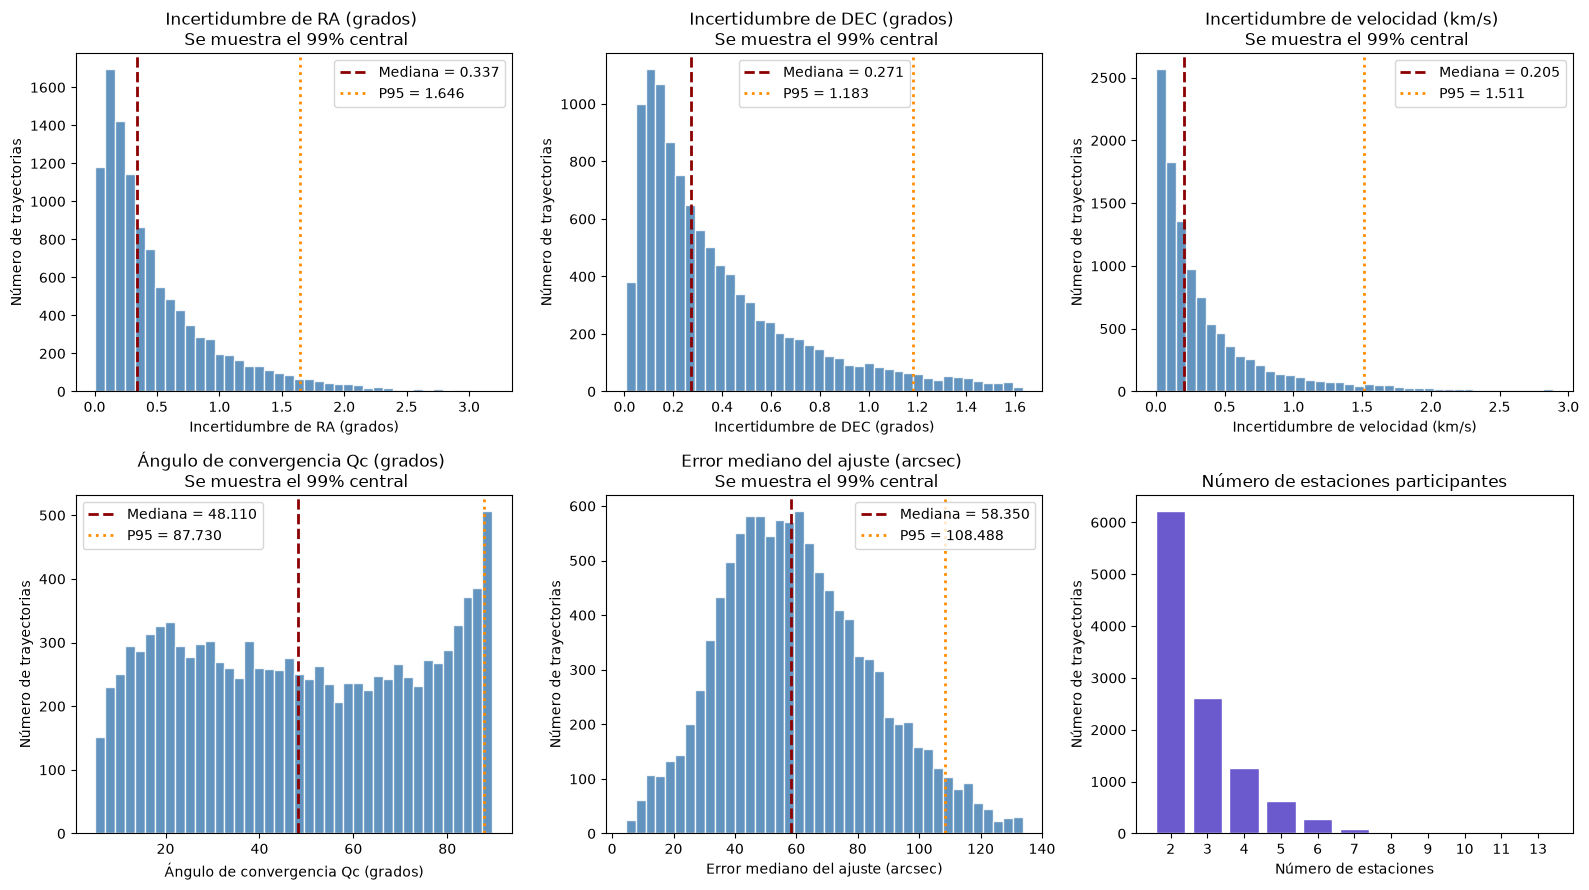

In [58]:
# Visualizar las distribuciones centrales de los indicadores de calidad de las trayectorias

variables_continuas_calidad = {
    "RAgeo_sigma": "Incertidumbre de RA (grados)",
    "DECgeo_sigma": "Incertidumbre de DEC (grados)",
    "Vgeo_sigma": "Incertidumbre de velocidad (km/s)",
    "Qc (deg)": "Ángulo de convergencia Qc (grados)",
    "MedianFitErr (arcsec)": "Error mediano del ajuste (arcsec)",
}

figura, ejes = plt.subplots(
    nrows = 2,
    ncols = 3,
    figsize = (16, 9),
)

ejes = ejes.flatten()

for eje, (columna, etiqueta) in zip(ejes, variables_continuas_calidad.items()):
    percentil_99 = df[columna].quantile(0.99)
    datos_centrales = df.loc[df[columna] <= percentil_99, columna]
    mediana = df[columna].median()
    percentil_95 = df[columna].quantile(0.95)
    
    eje.hist(
        datos_centrales,
        bins = 40,
        color = "steelblue",
        edgecolor = "white",
        alpha = 0.85,
    )
    
    eje.axvline(
        mediana,
        color = "darkred",
        linestyle = "--",
        linewidth = 2,
        label = f"Mediana = {mediana:.3f}",
    )
    
    eje.axvline(
        percentil_95,
        color = "darkorange",
        linestyle = ":",
        linewidth = 2,
        label = f"P95 = {percentil_95:.3f}",
    )
    
    eje.set_title(f"{etiqueta} \n Se muestra el 99% central")
    eje.set_xlabel(etiqueta)
    eje.set_ylabel("Número de trayectorias")
    eje.legend()
    
conteo_estaciones = (df["Num (stat)"].value_counts().sort_index())

ejes[5].bar(
    conteo_estaciones.index.astype(str),
    conteo_estaciones.values,
    color = "slateblue",
    edgecolor = "white",
)

ejes[5].set_title("Número de estaciones participantes")
ejes[5].set_xlabel("Número de estaciones")
ejes[5].set_ylabel("Número de trayectorias")

plt.tight_layout()
plt.show()

In [60]:
# Comparar las medianas de los indicadores de calidad según el ángulo Qc y el número de estaciones

intervalos_qc = [
    0,
    10,
    15,
    30,
    45,
    60,
    75,
    90,
]

etiquetas_qc = [
    "0–10",
    "10–15",
    "15–30",
    "30–45",
    "45–60",
    "60–75",
    "75–90",
]

df["grupo_qc"] = pd.cut(
    df["Qc (deg)"],
    bins = intervalos_qc,
    labels = etiquetas_qc,
    include_lowest = True,
    right = True,
)

resumen_por_qc = (
    df.groupby("grupo_qc", observed = False)
    .agg(
        trayectorias = (
            "Unique trajectory (identifier)", 
            "size"
        ),
        ra_sigma_mediana = (
            "RAgeo_sigma",
            "median",
        ),
        dec_sigma_mediana = (
            "DECgeo_sigma",
            "median",
        ),
        vgeo_sigma_mediana = (
            "Vgeo_sigma",
            "median",
        ),
        error_ajuste_mediano = (
            "MedianFitErr (arcsec)",
            "median",
        ),
        estaciones_mediana = (
            "Num (stat)", 
            "median",
        ),
    )
    .reset_index()
    .round(4)
)

print("Calidad según el ángulo de convergencia: ")
display(resumen_por_qc)

grupo_estaciones = (
    df["Num (stat)"]
    .astype("string")
    .mask(df["Num (stat)"] >= 7, "7+")
)

orden_estaciones = [
    "2",
    "3",
    "4",
    "5",
    "6",
    "7+",
]

df["grupo_estaciones"] = pd.Categorical(
    grupo_estaciones,
    categories = orden_estaciones,
    ordered = True,
)

resumen_por_estaciones = (
    df.groupby(
        "grupo_estaciones",
        observed = False,
    )
    .agg(
        
        trayectorias=(
            "Unique trajectory (identifier)",
            "size",
        ),
        qc_mediana=(
            "Qc (deg)",
            "median",
        ),
        ra_sigma_mediana=(
            "RAgeo_sigma",
            "median",
        ),
        dec_sigma_mediana=(
            "DECgeo_sigma",
            "median",
        ),
        vgeo_sigma_mediana=(
            "Vgeo_sigma",
            "median",
        ),
        error_ajuste_mediano=(
            "MedianFitErr (arcsec)",
            "median",
        ),
    )
    .reset_index()
    .round(4)
)

print("\nCalidad según el número de estaciones: ")
display(resumen_por_estaciones)

Calidad según el ángulo de convergencia: 


,grupo_qc,trayectorias,ra_sigma_mediana,dec_sigma_mediana,vgeo_sigma_mediana,error_ajuste_mediano,estaciones_mediana
0,0–10,474,0.9262,0.6093,0.3877,42.095,2.0
1,10–15,645,0.6910,0.5424,0.3578,47.470,2.0
2,15–30,2171,0.4492,0.3976,0.2946,51.620,2.0
3,30–45,1894,0.3672,0.3105,0.2472,58.060,2.0
4,45–60,1734,0.3102,0.2438,0.1912,59.485,2.0
5,60–75,1718,0.2813,0.2178,0.1625,62.990,3.0
6,75–90,2507,0.2317,0.1787,0.1256,66.160,3.0



Calidad según el número de estaciones: 


,grupo_estaciones,trayectorias,qc_mediana,ra_sigma_mediana,dec_sigma_mediana,vgeo_sigma_mediana,error_ajuste_mediano
0,2,6210,39.175,0.3915,0.3286,0.2622,51.175
1,3,2615,50.180,0.3525,0.2671,0.1940,63.410
2,4,1264,68.170,0.2560,0.1889,0.1287,67.020
3,5,627,79.140,0.2143,0.1650,0.1123,72.360
4,6,282,83.880,0.1780,0.1385,0.0822,74.580
5,7+,145,86.570,0.1231,0.0897,0.0557,77.820


In [61]:
# Comparar la precisión por número de estacioens dentro de intervalos semejantes de Qc

df["grupo_qc_reducido"] = pd.cut(
    df["Qc (deg)"],
    bins = [
        0,
        15,
        30,
        60,
        90,
    ],
    labels = [
        "0–15",
        "15–30",
        "30–60",
        "60–90",
    ],
    include_lowest = True,
    right = True,
)

grupo_estaciones_reducido = (
    df["Num (stat)"]
    .astype("string")
    .mask(
        df["Num (stat)"] >= 4,
        "4+",
    )
)

df["grupo_estaciones_reducido"] = pd.Categorical(
    grupo_estaciones_reducido,
    categories = [
        "2",
        "3",
        "4+",
    ],
    ordered = True,
)

resumen_combinado = (
    df.groupby(
        [
            "grupo_qc_reducido",
            "grupo_estaciones_reducido",
        ],
        observed = False,
    )
    .agg(
        trayectorias=(
            "Unique trajectory (identifier)",
            "size",
        ),
        ra_sigma_mediana=(
            "RAgeo_sigma",
            "median",
        ),
        dec_sigma_mediana=(
            "DECgeo_sigma",
            "median",
        ),
        vgeo_sigma_mediana=(
            "Vgeo_sigma",
            "median",
        ),
        error_ajuste_mediano=(
            "MedianFitErr (arcsec)",
            "median",
        ),
    )
    .reset_index()
    .round(4)
)

display(resumen_combinado)

,grupo_qc_reducido,grupo_estaciones_reducido,trayectorias,ra_sigma_mediana,dec_sigma_mediana,vgeo_sigma_mediana,error_ajuste_mediano
0,0–15,2,865,0.8114,0.5994,0.4141,42.190
1,0–15,3,203,0.7266,0.5069,0.2968,55.310
2,0–15,4+,51,0.6407,0.3282,0.1880,57.970
3,15–30,2,1468,0.4598,0.4100,0.3163,47.285
4,15–30,3,510,0.4524,0.3873,0.2842,61.505
5,15–30,4+,193,0.3406,0.3093,0.1983,65.460
6,30–60,2,2301,0.3485,0.2952,0.2365,53.460
7,30–60,3,861,0.3538,0.2694,0.2094,65.710
8,30–60,4+,466,0.2715,0.2198,0.1684,71.645
9,60–90,2,1576,0.2999,0.2375,0.2081,58.150


In [64]:
# Calcular una incertidumbre angular aproximada del radiante y auditar Vavg_sigma

import numpy as np

declinacion_radianes = np.deg2rad(
    df["DECgeo (deg)"]
)

df["RAgeo_sigma_cielo"] = (
    df["RAgeo_sigma"]
    * np.cos(declinacion_radianes)
)

df["sigma_radiante_aprox"] = np.hypot(
    df["RAgeo_sigma_cielo"],
    df["DECgeo_sigma"],
)

df["flag_vavg_sigma_cero"] = (
    df["Vavg_sigma"].eq(0)
)

columnas_nuevas_calidad = [
    "RAgeo_sigma_cielo",
    "sigma_radiante_aprox",
    "Vavg_sigma",
]

resumen_nuevas_variables = (
    df[columnas_nuevas_calidad]
    .describe(
        percentiles=[
            0.01,
            0.05,
            0.25,
            0.50,
            0.75,
            0.95,
            0.99,
        ]
    )
    .T
    .rename(
        columns={
            "count": "cantidad",
            "mean": "media",
            "std": "desviacion_estandar",
            "min": "minimo",
            "1%": "percentil_1",
            "5%": "percentil_5",
            "25%": "percentil_25",
            "50%": "mediana",
            "75%": "percentil_75",
            "95%": "percentil_95",
            "99%": "percentil_99",
            "max": "maximo",
        }
    )
    .round(4)
)

display(resumen_nuevas_variables)

cantidad_vavg_sigma_cero = (
    df["flag_vavg_sigma_cero"].sum()
)

porcentaje_vavg_sigma_cero = (
    100
    * cantidad_vavg_sigma_cero
    / len(df)
)

print(
    "Trayectorias con Vavg_sigma igual a cero:",
    cantidad_vavg_sigma_cero,
)

print(
    "Porcentaje:",
    round(
        porcentaje_vavg_sigma_cero,
        4,
    ),
    "%",
)

,cantidad,media,desviacion_estandar,minimo,percentil_1,percentil_5,percentil_25,mediana,percentil_75,percentil_95,percentil_99,maximo
RAgeo_sigma_cielo,11143.0,0.3966,0.3645,0.0053,0.0199,0.0457,0.1344,0.2737,0.5410,1.1980,1.6561,1.9801
sigma_radiante_aprox,11143.0,0.6014,0.4619,0.0088,0.0469,0.0956,0.2432,0.4644,0.8403,1.5956,1.9051,1.9992
Vavg_sigma,11143.0,0.2934,0.4938,0.0008,0.0038,0.0100,0.0448,0.1224,0.3192,1.1785,2.3766,9.8494


Trayectorias con Vavg_sigma igual a cero: 0
Porcentaje: 0.0 %


In [67]:
# Construir muestras provisionales de calidad y cuantificar cuántas trayectorias y Gemínidas conserva cada una

df["cumple_qc_15"] = (
    df["Qc (deg)"].ge(15)
)

df["cumple_error_ajuste_60"] = (
    df["MedianFitErr (arcsec)"].le(60)
)

df["cumple_vavg_sigma_1"] = (
    df["Vavg_sigma"].gt(0)
    & df["Vavg_sigma"].le(1)
)

df["cumple_sigma_radiante_025"] = (
    df["sigma_radiante_aprox"].le(0.25)
)

df["calidad_radiante_publicada"] = (
    df["cumple_qc_15"]
    & df["cumple_error_ajuste_60"]
    & df["cumple_vavg_sigma_1"]
    & df["cumple_sigma_radiante_025"]
)

df["fov_completo"] = (
    df["Beg in (FOV)"]
    & df["End in (FOV)"]
)

df["calidad_estandar_provisional"] = (
    df["calidad_radiante_publicada"]
    & df["fov_completo"]
)

df["calidad_estricta_provisional"] = (
    df["calidad_estandar_provisional"]
    & df["Num (stat)"].ge(4)
)

criterios_individuales = {
    "Qc ≥ 15 grados": "cumple_qc_15",
    "Error de ajuste ≤ 60 arcsec": "cumple_error_ajuste_60",
    "0 < Vavg_sigma ≤ 1 km/s": "cumple_vavg_sigma_1",
    "Sigma del radiante ≤ 0.25 grados": "cumple_sigma_radiante_025",
    "Comienzo y final dentro del FOV": "fov_completo",
    "Cuatro o más estaciones": "Num (stat)",
}

resultados_criterios = []

for descripcion, columna in criterios_individuales.items():
    if columna == "Num (stat)":
        mascara = df[columna].ge(4)
    else:
        mascara = df[columna]
        
    cantidad = mascara.sum()
    
    resultados_criterios.append(
        {
            "criterio": descripcion,
            "cumplen": cantidad,
            "no_cumplen": len(df) - cantidad,
            "porcentaje_que_cumple": round(
                100 * cantidad / len(df),
                2,
            ),
        }
    )
    
resumen_criterios = pd.DataFrame(
        resultados_criterios
)
    
print("Retención de cada criterio por separado: ")
display(resumen_criterios)

es_geminida = df["IAU (code)"].eq("GEM")

muestras_provisionales = {
    "Base completa": pd.Series(
        True,
        index = df.index,
    ),
    "Calidad radiante publicada": (
        df["calidad_radiante_publicada"]
    ),
    "Estándar provisional": (
        df["calidad_estandar_provisional"]
    ),
    "Estricta provisional": (
        df["calidad_estricta_provisional"]
    ),
}

resultados_muestras = []

for nombre, mascara in muestras_provisionales.items():
    cantidad_total = mascara.sum()
    cantidad_geminidas = (
        mascara
        & es_geminida
    ).sum()
    
    resultados_muestras.append(
        {
            "muestra": nombre,
            "trayectorias_totales": cantidad_total,
            "porcentaje_de_la_base": round(
                100 * cantidad_total / len(df),
                2,
            ),
            "geminidas": cantidad_geminidas,
        }
    )
    
resumen_muestras = pd.DataFrame(
    resultados_muestras
)

print("\nRetención de las muestras combinadas: ")
display(resumen_muestras)

Retención de cada criterio por separado: 


,criterio,cumplen,no_cumplen,porcentaje_que_cumple
0,Qc ≥ 15 grados,10024,1119,89.96
1,Error de ajuste ≤ 60 arcsec,5846,5297,52.46
2,0 < Vavg_sigma ≤ 1 km/s,10390,753,93.24
3,Sigma del radiante ≤ 0.25 grados,2888,8255,25.92
4,Comienzo y final dentro del FOV,11050,93,99.17
5,Cuatro o más estaciones,2318,8825,20.80



Retención de las muestras combinadas: 


,muestra,trayectorias_totales,porcentaje_de_la_base,geminidas
0,Base completa,11143,100.00,2117
1,Calidad radiante publicada,1961,17.60,452
2,Estándar provisional,1934,17.36,443
3,Estricta provisional,457,4.10,99


In [69]:
# Evaluar si los filtros de calidad retienen de forma diferente Gemínidas brillantes y débiles

geminidas_2019 = (
    df.loc[
        df["IAU (code)"].eq("GEM")
    ]
    .copy()
)

bordes_magnitud = np.arange(-5, 6, 1)

geminidas_2019["intervalo_magnitud"] = pd.cut(
    geminidas_2019["Peak (AbsMag)"],
    bins=bordes_magnitud,
    include_lowest=True,
    right=False,
)

retencion_por_magnitud = (
    geminidas_2019.groupby(
        "intervalo_magnitud",
        observed = False,
    )
    .agg(
        geminidas_totales = (
            "Unique trajectory (identifier)",
            "size",
        ),
        geminidas_estandar = (
            "calidad_estandar_provisional",
            "sum",
        ),
        geminidas_estrictas = (
            "calidad_estricta_provisional",
            "sum",
        ),
    )
    .reset_index()
)

retencion_por_magnitud = (
    retencion_por_magnitud.loc[
        retencion_por_magnitud["geminidas_totales"] > 0
    ]
    .copy()
)

retencion_por_magnitud["retencion_estandar_porcentaje"] = (
    100
    * retencion_por_magnitud["geminidas_estandar"]
    / retencion_por_magnitud["geminidas_totales"]
)

retencion_por_magnitud["retencion_estricta_porcentaje"] = (
    100
    * retencion_por_magnitud["geminidas_estrictas"]
    / retencion_por_magnitud["geminidas_totales"]
)

retencion_por_magnitud = (retencion_por_magnitud.round(2))

print("Retención de Gemínidas según magnitud: ")
display(retencion_por_magnitud)

resumen_magnitud_muestras = pd.DataFrame(
    {
        "muestra": [
            "Gemínidas completas",
            "Gemínidas estándar",
            "Gemínidas estrictas",
        ],
        "cantidad": [
            len(geminidas_2019),
            geminidas_2019[
                "calidad_estandar_provisional"
            ].sum(),
            geminidas_2019[
                "calidad_estricta_provisional"
            ].sum(),
        ],
        "magnitud_media": [
            geminidas_2019[
                "Peak (AbsMag)"
            ].mean(),
            geminidas_2019.loc[
                geminidas_2019[
                    "calidad_estandar_provisional"
                ],
                "Peak (AbsMag)",
            ].mean(),
            geminidas_2019.loc[
                geminidas_2019[
                    "calidad_estricta_provisional"
                ],
                "Peak (AbsMag)",
            ].mean(),
        ],
        "magnitud_mediana": [
            geminidas_2019[
                "Peak (AbsMag)"
            ].median(),
            geminidas_2019.loc[
                geminidas_2019[
                    "calidad_estandar_provisional"
                ],
                "Peak (AbsMag)",
            ].median(),
            geminidas_2019.loc[
                geminidas_2019[
                    "calidad_estricta_provisional"
                ],
                "Peak (AbsMag)",
            ].median(),
        ],
    }
).round(3)

print("\nComparación general de magnitud: ")
display(resumen_magnitud_muestras)

Retención de Gemínidas según magnitud: 


,intervalo_magnitud,geminidas_totales,geminidas_estandar,geminidas_estrictas,retencion_estandar_porcentaje,retencion_estricta_porcentaje
1,"[-4, -3)",3,0,0,0.00,0.00
2,"[-3, -2)",64,10,4,15.62,6.25
3,"[-2, -1)",454,103,30,22.69,6.61
4,"[-1, 0)",810,195,46,24.07,5.68
5,"[0, 1)",570,103,14,18.07,2.46
6,"[1, 2)",189,25,4,13.23,2.12
7,"[2, 3)",25,6,1,24.00,4.00
8,"[3, 4)",2,1,0,50.00,0.00



Comparación general de magnitud: 


,muestra,cantidad,magnitud_media,magnitud_mediana
0,Gemínidas completas,2117,-0.302,-0.35
1,Gemínidas estándar,443,-0.399,-0.47
2,Gemínidas estrictas,99,-0.633,-0.72


In [73]:
# Identificar qué criterios de calidad dependen del brillo y comparar la calidad residual de la muestra estándar

geminidas_2019["grupo_brillo"] = pd.cut(
    geminidas_2019["Peak (AbsMag)"],
    bins = [-np.inf, -1, 0, 1, np.inf],
    labels = ["M ≤ -1", "-1 < M ≤ 0", "0 < M ≤ 1", "M > 1"],
    include_lowest = True,
    right = True
)

diagnostico_filtros_brillo = (
    geminidas_2019.groupby("grupo_brillo", observed = False)
    .agg(
        geminidas_totales = (
            "Unique trajectory (identifier)", 
            "size",
        ),
        cumple_qc_15 = (
            "cumple_qc_15",
            "mean",
        ),
        cumple_error_ajuste_60=(
            "cumple_error_ajuste_60",
            "mean",
        ),
        cumple_vavg_sigma_1=(
            "cumple_vavg_sigma_1",
            "mean",
        ),
        cumple_sigma_radiante_025=(
            "cumple_sigma_radiante_025",
            "mean",
        ),
        cumple_fov_completo=(
            "fov_completo",
            "mean",
        ),
        cumple_estandar=(
            "calidad_estandar_provisional",
            "mean",
        ),
        cumple_estricta=(
            "calidad_estricta_provisional",
            "mean",
        ),
    )
    .reset_index()
)

columnas_porcentaje = [
    "cumple_qc_15",
    "cumple_error_ajuste_60",
    "cumple_vavg_sigma_1",
    "cumple_sigma_radiante_025",
    "cumple_fov_completo",
    "cumple_estandar",
    "cumple_estricta",
]

diagnostico_filtros_brillo[columnas_porcentaje] = 100 * diagnostico_filtros_brillo[columnas_porcentaje]

diagnostico_filtros_brillo = diagnostico_filtros_brillo.round(2)

print("Porcentaje que supera cada criterio según brillo: ")
display(diagnostico_filtros_brillo)

geminidas_estandar_2019 = (
    geminidas_2019.loc[
        geminidas_2019[
            "calidad_estandar_provisional"
        ]
    ]
    .copy()
)

calidad_residual_por_brillo = (
    geminidas_estandar_2019.groupby(
        "grupo_brillo",
        observed=False,
    )
    .agg(
        geminidas=(
            "Unique trajectory (identifier)",
            "size",
        ),
        sigma_radiante_mediana=(
            "sigma_radiante_aprox",
            "median",
        ),
        qc_mediana=(
            "Qc (deg)",
            "median",
        ),
        vavg_sigma_mediana=(
            "Vavg_sigma",
            "median",
        ),
        error_ajuste_mediano=(
            "MedianFitErr (arcsec)",
            "median",
        ),
        estaciones_mediana=(
            "Num (stat)",
            "median",
        ),
    )
    .reset_index()
    .round(4)
)

print("\n Calidad restante dentro de la muestra estándar: ")

display(calidad_residual_por_brillo)



Porcentaje que supera cada criterio según brillo: 


,grupo_brillo,geminidas_totales,cumple_qc_15,cumple_error_ajuste_60,cumple_vavg_sigma_1,cumple_sigma_radiante_025,cumple_fov_completo,cumple_estandar,cumple_estricta
0,M ≤ -1,531,91.90,50.09,99.44,41.62,98.68,21.47,6.40
1,-1 < M ≤ 0,806,93.80,60.79,98.64,31.89,99.26,24.07,5.71
2,0 < M ≤ 1,568,93.49,58.10,96.65,22.89,99.47,18.13,2.46
3,M > 1,212,90.57,56.60,96.70,18.87,95.75,15.09,2.36



 Calidad restante dentro de la muestra estándar: 


,grupo_brillo,geminidas,sigma_radiante_mediana,qc_mediana,vavg_sigma_mediana,error_ajuste_mediano,estaciones_mediana
0,M ≤ -1,114,0.1480,68.92,0.0152,48.685,3.0
1,-1 < M ≤ 0,194,0.1555,66.01,0.0276,43.950,3.0
2,0 < M ≤ 1,103,0.1619,61.22,0.0446,37.380,2.0
3,M > 1,32,0.1755,43.31,0.0588,18.470,2.0
